# Part 4C: The intercept as a performance drag

**Question.** Annualize the regression intercept (multiply by 252 trading days). Does it roughly align with the stated net operating expense ratio of 1.15% per annum? Name two other expenses that may be reflected in the drag.

**Method.** Re-estimate the 4B regression, annualize alpha and its 95% confidence interval, and compare with the expense figures on the NVDL factsheet (as of 2024-06-30).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format
# Paths are relative to part4/python_source
DATA = next(Path("../../data/raw").glob("*part 4*.xlsx"))
OUT = Path("../../output/part4"); OUT.mkdir(parents=True, exist_ok=True)

# 5 header rows, then newest-first daily total returns in decimals (0.01 = 1%)
raw = pd.read_excel(DATA, header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")   # ascending order needed before compounding
print(len(df), "trading days,", df.index.min().date(), "to", df.index.max().date())

147 trading days, 2024-02-01 to 2024-08-30


In [2]:
import statsmodels.api as sm

ols = sm.OLS(df["NVDL"], sm.add_constant(df["NVDA"])).fit()
a = ols.params["const"]; lo, hi = ols.conf_int(0.05).loc["const"]

summary = pd.DataFrame({
    "Daily": [a, lo, hi],
    "Annualized (x252)": [a * 252, lo * 252, hi * 252],
}, index=["Intercept estimate", "95% CI low", "95% CI high"])
summary.to_csv(OUT / "4C_alpha.csv")
print(summary.apply(lambda col: col.map(lambda v: f"{v:.4%}")).to_string())

# Model-free cross-check: average daily gap between NVDL and exactly twice NVDA
gap = (df["NVDL"] - 2 * df["NVDA"]).mean()
print(f"\nCross-check, mean(NVDL - 2*NVDA) x 252 = {gap * 252:.2%}")

                       Daily Annualized (x252)
Intercept estimate  -0.0612%         -15.4134%
95% CI low          -0.0935%         -23.5523%
95% CI high         -0.0289%          -7.2745%

Cross-check, mean(NVDL - 2*NVDA) x 252 = -15.94%


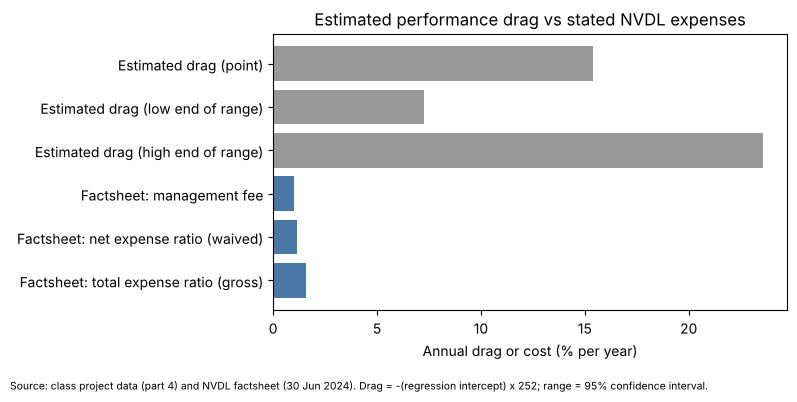

In [3]:
compare = pd.DataFrame({
    "Annual cost / drag": [-a * 252, -hi * 252, -lo * 252, 0.0099, 0.0115, 0.0157],
}, index=["Estimated drag (point)", "Estimated drag (low end of range)", "Estimated drag (high end of range)",
          "Factsheet: management fee", "Factsheet: net expense ratio (waived)", "Factsheet: total expense ratio (gross)"])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(compare.index[::-1], compare["Annual cost / drag"][::-1] * 100,
        color=["#999", "#999", "#999", "#4C78A8", "#4C78A8", "#4C78A8"][::-1])
ax.set_xlabel("Annual drag or cost (% per year)")
ax.set_title("Estimated performance drag vs stated NVDL expenses")
fig.text(0.01, -0.04, "Source: class project data (part 4) and NVDL factsheet (30 Jun 2024). Drag = -(regression intercept) x 252; "
         "range = 95% confidence interval.", fontsize=7.5)
plt.tight_layout(); fig.savefig(OUT / "4C_drag_vs_expense.png", bbox_inches="tight"); plt.show()

## Comment

The annualized intercept is about -15% per year, with a 95% confidence interval of roughly -24% to -7%. This is far larger than the stated net expense ratio of 1.15% (and also larger than the 0.99% management fee and the 1.57% gross expense ratio), and 1.15% lies well outside the confidence interval. The regression intercept is noisy, since only seven months of daily data are used, but even the least negative end of the range is several times the stated expense ratio. So the drag does not align with the published fee.

The expense ratio is only part of what a daily-rebalanced leveraged fund costs. Two other costs that plausibly show up in the estimated drag:

1. **Financing (borrowing) cost of the leverage.** To hold about 2x exposure the fund must borrow roughly one extra dollar of NVDA exposure per dollar of assets, typically through swaps or margin, at a short-term interest rate plus a spread. With short-term rates around 5% in 2024, this alone is a multiple of the expense ratio and is not included in it.
2. **Trading and rebalancing costs.** The fund must trade NVDA exposure every day to restore 2x leverage, buying after rallies and selling after declines. Bid-ask spreads, market impact and swap or futures roll costs on these trades reduce returns and are largely not in the expense ratio.

Smaller contributors include tracking differences from the timing of the fund's rebalancing and the closing prices used, and estimation noise in the intercept itself.